In [108]:
from IPython.display import display

import pandas as pd
import numpy as np
from pathlib import Path
import unicodedata

repo = Path("CS418-Project")

artists = [
    "Morgan Wallen", "Tame Impala", "Bruno Mars",
    "Ella Langley", "Steve Lacy", "Olivia Rodrigo",
    "Sam Fender", "Shaboozey", "Luke Combs",
    "ADELA", "Jamie Miller", "Cameron Whitcomb",
    "Taylor Swift", "JENNIE", "Malcolm Todd",
    "sombr", "Lainey Wilson", "Yung Miami",
    "Beyonce", "Audrey Hobert", "Ty Dolla $ign",
    "Olivia Dean", "Stella Lefty", "Burna Boy"
]

songs = [
    "Last Thing You Need", "Dracula", "Risk It All",
    "Choosin' Texas", "Oh Yeah?", "Stupid Song",
    "Rein Me in", "Cowgirl", "Rethink Some Things",
    "Nicole Kidman", "Babydoll", "Kingdom Of Fear",
    "Patient Zero", "Dracula", "Earrings",
    "My Body Isn't Ready", "Phone, Keys, Wallet",
    "Spend Dat", "Morning Dew (Donk)", "Sue Me",
    "Cinderella", "Rein Me In", "Boston",
    "Dai Dai (FIFA World Cup Official Song 2026)"
]

plant = [0] * 12 + [1] * 12

radio_spins = [
    13668, np.nan, 11556, 21527,
    np.nan, 14450, np.nan, np.nan,
    18672, np.nan, np.nan, np.nan,
    15523, 17981, 11087, 12311,
    15330, np.nan, np.nan, np.nan,
    np.nan, np.nan, 27726, np.nan
]

weeks_on_chart = [
    7, 32, 36, 55, 14, 21,
    30, 18, 32, 9, 7, 13,
    6, 32, 36, 19, 22, 20,
    18, 15, 23, 30, 31, 20
]

df = pd.DataFrame({
    "Artist": artists,
    "Song": songs,
    "Plant": plant,
    "Radio_Spins": radio_spins,
    "Weeks_on_Chart": weeks_on_chart
})

display(df)
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

,Artist,Song,Plant,Radio_Spins,Weeks_on_Chart
0,Morgan Wallen,Last Thing You Need,0,13668.0,7
1,Tame Impala,Dracula,0,NaN,32
2,Bruno Mars,Risk It All,0,11556.0,36
3,Ella Langley,Choosin' Texas,0,21527.0,55
4,Steve Lacy,Oh Yeah?,0,NaN,14
5,Olivia Rodrigo,Stupid Song,0,14450.0,21
6,Sam Fender,Rein Me in,0,NaN,30
7,Shaboozey,Cowgirl,0,NaN,18
8,Luke Combs,Rethink Some Things,0,18672.0,32
9,ADELA,Nicole Kidman,0,NaN,9


Dataset shape: (24, 5)

Missing values:
Artist             0
Song               0
Plant              0
Radio_Spins       13
Weeks_on_Chart     0
dtype: int64


In [109]:

import pandas as pd
import numpy as np
import re
import unicodedata
from pathlib import Path
from IPython.display import display

# Repository containing the team datasets
repo = Path("CS418-Project")

# Start fresh from the original five-column artist dataset
base_columns = [
    "Artist", "Song", "Plant",
    "Radio_Spins", "Weeks_on_Chart"
]

df = df[base_columns].copy()

# Load team datasets
audience = pd.read_csv(
    repo / "Audience SIze by Career Age - Sheet1.csv"
)

networth = pd.read_csv(repo / "networth.csv")

streaming = pd.read_csv(
    repo / "streamvsplaylists.csv"
)

# Normalize artist names for audience and net worth joins
def clean_name(value):
    return re.sub(
        r"\s+", " ", str(value).strip()
    ).casefold()

df["Artist_Key"] = df["Artist"].apply(clean_name)
audience["Artist_Key"] = audience["Artist"].apply(clean_name)
networth["Artist_Key"] = networth["Artist"].apply(clean_name)

# Convert audience values to numeric
audience["Monthly_Listeners"] = pd.to_numeric(
    audience["Spotify monthly listeners"]
        .astype(str)
        .str.replace(",", "", regex=False),
    errors="coerce"
)

audience["Months since first release"] = pd.to_numeric(
    audience["Months since first release"]
        .astype(str)
        .str.replace(",", "", regex=False),
    errors="coerce"
)

# Merge audience data
df = df.merge(
    audience[
        [
            "Artist_Key",
            "Monthly_Listeners",
            "Months since first release"
        ]
    ],
    on="Artist_Key",
    how="left",
    validate="one_to_one"
)

# Merge net worth
df = df.merge(
    networth[["Artist_Key", "Networth"]],
    on="Artist_Key",
    how="left",
    validate="one_to_one"
)

# Split streaming song and artist names
streaming[["Stream_Song", "Stream_Artist"]] = (
    streaming["SongArtist"]
    .str.rsplit(" by ", n=1, expand=True)
)

# Correct Morgan Wallen's song title before merging
morgan_mask = (
    streaming["Stream_Artist"]
    .str.strip()
    .eq("Morgan Wallen")
    &
    streaming["Stream_Song"]
    .str.strip()
    .eq("Been By Now")
)

streaming.loc[
    morgan_mask, "Stream_Song"
] = "Last Thing You Need"

streaming.loc[
    morgan_mask, "SongArtist"
] = "Last Thing You Need by Morgan Wallen"

# Normalize artist and song names for streaming joins
def song_key(value):
    if pd.isna(value):
        return ""

    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(
        c for c in value
        if not unicodedata.combining(c)
    )

    return re.sub(r"[\W_]+", "", value.casefold())

df["Stream_Artist_Key"] = df["Artist"].apply(song_key)
df["Song_Key"] = df["Song"].apply(song_key)

streaming["Stream_Artist_Key"] = (
    streaming["Stream_Artist"].apply(song_key)
)

streaming["Song_Key"] = (
    streaming["Stream_Song"].apply(song_key)
)

# Merge streaming data using BOTH artist and song
df = df.merge(
    streaming[
        [
            "Stream_Artist_Key",
            "Song_Key",
            "Stream_Song",
            "Streams",
            "Playlists"
        ]
    ],
    on=["Stream_Artist_Key", "Song_Key"],
    how="left",
    validate="one_to_one"
)

# Convert streaming statistics to numeric
for col in ["Streams", "Playlists"]:
    df[col] = pd.to_numeric(
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

# Check final dataset
print("Combined dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMorgan Wallen record:")
display(
    df.loc[
        df["Artist"] == "Morgan Wallen",
        ["Artist", "Song", "Streams", "Playlists"]
    ]
)

print("\nMissing streaming records:")
display(
    df.loc[
        df["Streams"].isna(),
        ["Artist", "Song", "Streams", "Playlists"]
    ]
)


Combined dataset shape: (24, 14)

Columns:
['Artist', 'Song', 'Plant', 'Radio_Spins', 'Weeks_on_Chart', 'Artist_Key', 'Monthly_Listeners', 'Months since first release', 'Networth', 'Stream_Artist_Key', 'Song_Key', 'Stream_Song', 'Streams', 'Playlists']

Morgan Wallen record:


,Artist,Song,Streams,Playlists
0,Morgan Wallen,Last Thing You Need,100615684.0,1086.0



Missing streaming records:


,Artist,Song,Streams,Playlists
2,Bruno Mars,Risk It All,NaN,NaN
8,Luke Combs,Rethink Some Things,NaN,NaN


In [110]:
!git clone https://github.com/lfern101/CS418-Project.git

fatal: destination path 'CS418-Project' already exists and is not an empty directory.


In [111]:
# Check all artists, songs, and labels
display(
    df[
        ["Artist", "Song", "Plant", "Radio_Spins", "Weeks_on_Chart"]
    ].sort_values("Artist").reset_index(drop=True)
)

print("Total artists:", len(df))
print("\nPlant label distribution:")
print(df["Plant"].value_counts())

print("\nDuplicate artist-song records:")
print(df.duplicated(subset=["Artist", "Song"]).sum())

,Artist,Song,Plant,Radio_Spins,Weeks_on_Chart
0,ADELA,Nicole Kidman,0,NaN,9
1,Audrey Hobert,Sue Me,1,NaN,15
2,Beyonce,Morning Dew (Donk),1,NaN,18
3,Bruno Mars,Risk It All,0,11556.0,36
4,Burna Boy,Dai Dai (FIFA World Cup Official Song 2026),1,NaN,20
5,Cameron Whitcomb,Kingdom Of Fear,0,NaN,13
6,Ella Langley,Choosin' Texas,0,21527.0,55
7,JENNIE,Dracula,1,17981.0,32
8,Jamie Miller,Babydoll,0,NaN,7
9,Lainey Wilson,"Phone, Keys, Wallet",1,15330.0,22


Total artists: 24

Plant label distribution:
Plant
0    12
1    12
Name: count, dtype: int64

Duplicate artist-song records:
0


In [112]:
import pandas as pd
import numpy as np
import re

# Load team datasets
audience = pd.read_csv(
    repo / "Audience SIze by Career Age - Sheet1.csv"
)

networth = pd.read_csv(repo / "networth.csv")

streaming = pd.read_csv(
    repo / "streamvsplaylists.csv"
)

In [113]:
print(df.columns.tolist())

['Artist', 'Song', 'Plant', 'Radio_Spins', 'Weeks_on_Chart', 'Artist_Key', 'Monthly_Listeners', 'Months since first release', 'Networth', 'Stream_Artist_Key', 'Song_Key', 'Stream_Song', 'Streams', 'Playlists']


In [114]:
display(
    df.loc[
        df["Artist"].isin(["Luke Combs", "Bruno Mars"]),
        ["Artist", "Song", "Streams", "Playlists"]
    ]
)

,Artist,Song,Streams,Playlists
2,Bruno Mars,Risk It All,NaN,NaN
8,Luke Combs,Rethink Some Things,NaN,NaN


In [115]:

features = [
    "Radio_Spins",
    "Weeks_on_Chart",
    "Monthly_Listeners",
    "Streams",
    "Playlists",
    "Networth"
]

print("Available values for each feature:")
print(df[features].notna().sum())

print("\nArtists missing streaming data:")
display(
    df.loc[
        df["Streams"].isna(),
        ["Artist", "Song", "Plant"]
    ]
)

print("\nArtists missing monthly listeners:")
display(
    df.loc[
        df["Monthly_Listeners"].isna(),
        ["Artist", "Plant"]
    ]
)


Available values for each feature:
Radio_Spins          11
Weeks_on_Chart       24
Monthly_Listeners    22
Streams              22
Playlists            22
Networth             24
dtype: int64

Artists missing streaming data:


,Artist,Song,Plant
2,Bruno Mars,Risk It All,0
8,Luke Combs,Rethink Some Things,0



Artists missing monthly listeners:


,Artist,Plant
9,ADELA,0
18,Beyonce,1


In [116]:

weeks = pd.read_csv(repo / "WeeksOnChart.csv")

weeks["Artist_Key"] = weeks["Artist"].apply(clean_name)

comparison = df[[
    "Artist", "Song", "Artist_Key", "Weeks_on_Chart"
]].merge(
    weeks[["Artist_Key", "Song", "WeeksOnChart"]],
    on="Artist_Key",
    how="left",
    suffixes=("_Selected", "_CSV"),
    validate="one_to_one"
)

display(comparison[[
    "Artist",
    "Song_Selected",
    "Song_CSV",
    "Weeks_on_Chart",
    "WeeksOnChart"
]])


,Artist,Song_Selected,Song_CSV,Weeks_on_Chart,WeeksOnChart
0,Morgan Wallen,Last Thing You Need,Last Thing You Need,7,7
1,Tame Impala,Dracula,Dracula,32,32
2,Bruno Mars,Risk It All,Risk It All,36,36
3,Ella Langley,Choosin' Texas,Choosin' Texas,55,55
4,Steve Lacy,Oh Yeah?,Oh Yeah?,14,14
5,Olivia Rodrigo,Stupid Song,Stupid Song,21,21
6,Sam Fender,Rein Me in,Rein Me in,30,30
7,Shaboozey,Cowgirl,Cowgirl,18,18
8,Luke Combs,Rethink Some Things,Rethink Some Things,32,32
9,ADELA,Nicole Kidman,Nicole Kidman,9,9


In [117]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

model_df = df.dropna(subset=["Streams", "Plant", "Radio_Spins"]).copy()
model_df["Streams_Millions"] = model_df["Streams"] / 1_000_000

print(f"Complete song matches: {len(model_df)} of {len(df)}")
display(model_df[["Artist", "Song", "Plant", "Streams", "Radio_Spins"]])

group_counts = model_df["Plant"].value_counts().reindex([0, 1], fill_value=0)
if group_counts.min() < 2:
    raise ValueError(
        "Need at least two complete song matches in each group "
        "so both groups are represented in every training fold."
    )

y = model_df["Radio_Spins"]

models = {
    "Mean baseline": (
        DummyRegressor(strategy="mean"), ["Streams_Millions"]
    ),
    "Streams only": (
        LinearRegression(), ["Streams_Millions"]
    ),
    "Streams + industry classification": (
        LinearRegression(), ["Streams_Millions", "Plant"]
    ),
}

results = []
predictions = {}

for name, (model, columns) in models.items():
    predicted = cross_val_predict(model, model_df[columns], y, cv=LeaveOneOut())
    predictions[name] = predicted

    results.append({
        "Model": name,
        "MAE (radio spins)": mean_absolute_error(y, predicted),
        "R²": r2_score(y, predicted),
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(2))

Complete song matches: 9 of 24


,Artist,Song,Plant,Streams,Radio_Spins
0,Morgan Wallen,Last Thing You Need,0,100615684.0,13668.0
3,Ella Langley,Choosin' Texas,0,833666224.0,21527.0
5,Olivia Rodrigo,Stupid Song,0,485727481.0,14450.0
12,Taylor Swift,Patient Zero,1,147560872.0,15523.0
13,JENNIE,Dracula,1,596728832.0,17981.0
14,Malcolm Todd,Earrings,1,846121458.0,11087.0
15,sombr,My Body Isn't Ready,1,165425881.0,12311.0
16,Lainey Wilson,"Phone, Keys, Wallet",1,23154635.0,15330.0
22,Stella Lefty,Boston,1,281532768.0,27726.0


,MAE (radio spins),R²
Model,,
Mean baseline,4341.58,-0.27
Streams only,4838.35,-0.64
Streams + industry classification,5751.33,-1.25


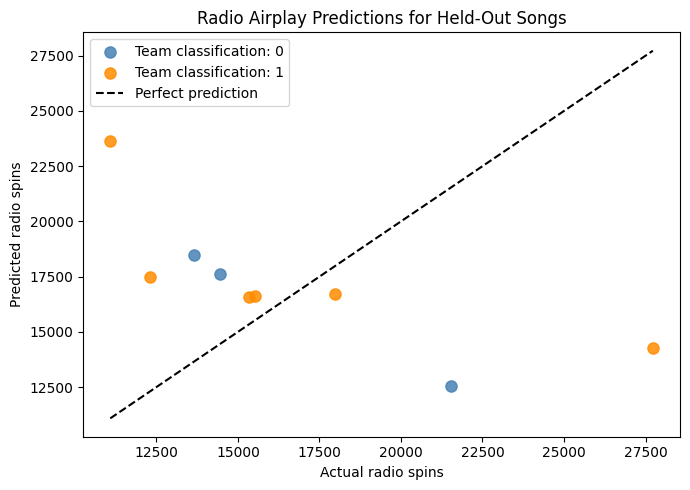

Streams only: 4,838 spins of average error
Streams + industry classification: 5,751 spins
Mean baseline: 4,342 spins


In [118]:
import matplotlib.pyplot as plt

full_model = "Streams + industry classification"
predicted = predictions[full_model]

low = min(y.min(), predicted.min())
high = max(y.max(), predicted.max())

plt.figure(figsize=(7, 5))

for group, color in [(0, "steelblue"), (1, "darkorange")]:
    mask = model_df["Plant"].eq(group).to_numpy()
    plt.scatter(
        y.to_numpy()[mask],
        predicted[mask],
        color=color,
        label=f"Team classification: {group}",
        s=65,
        alpha=0.85,
    )

plt.plot([low, high], [low, high], "k--", label="Perfect prediction")
plt.xlabel("Actual radio spins")
plt.ylabel("Predicted radio spins")
plt.title("Radio Airplay Predictions for Held-Out Songs")
plt.legend()
plt.tight_layout()
plt.show()

streams_mae = results_df.loc["Streams only", "MAE (radio spins)"]
full_mae = results_df.loc[full_model, "MAE (radio spins)"]
baseline_mae = results_df.loc["Mean baseline", "MAE (radio spins)"]

print(f"Streams only: {streams_mae:,.0f} spins of average error")
print(f"Streams + industry classification: {full_mae:,.0f} spins")
print(f"Mean baseline: {baseline_mae:,.0f} spins")

In [119]:
import pandas as pd
import numpy as np

# Original model: 4 features
features = [
    "Monthly_Listeners",
    "Streams",
    "Playlists",
    "Months since first release"
]

X = df[features].apply(
    pd.to_numeric,
    errors="coerce"
)

# Updated model: 5 features
features_v2 = features + ["Weeks_on_Chart"]

X_v2 = df[features_v2].apply(
    pd.to_numeric,
    errors="coerce"
)

# Target variable
y = df["Plant"].astype(int)

print("Original feature matrix:", X.shape)
print("Updated feature matrix:", X_v2.shape)
print("Target:", y.shape)

print("\nMissing values:")
print(X_v2.isnull().sum())

Original feature matrix: (24, 4)
Updated feature matrix: (24, 5)
Target: (24,)

Missing values:
Monthly_Listeners             2
Streams                       2
Playlists                     2
Months since first release    2
Weeks_on_Chart                0
dtype: int64


In [120]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=3,
            random_state=42
        )
    )
}

results = []
predictions_dict = {}

for name, model in models.items():
    predictions = cross_val_predict(
        model, X, y, cv=cv
    )

    predictions_dict[name] = predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0)
    })

    print(f"\n{name}")
    print(classification_report(y, predictions, zero_division=0))

results_df = pd.DataFrame(results)
display(results_df.round(3))



Baseline
              precision    recall  f1-score   support

           0       0.50      1.00      0.67        12
           1       0.00      0.00      0.00        12

    accuracy                           0.50        24
   macro avg       0.25      0.50      0.33        24
weighted avg       0.25      0.50      0.33        24


Logistic Regression
              precision    recall  f1-score   support

           0       0.50      0.33      0.40        12
           1       0.50      0.67      0.57        12

    accuracy                           0.50        24
   macro avg       0.50      0.50      0.49        24
weighted avg       0.50      0.50      0.49        24


Random Forest
              precision    recall  f1-score   support

           0       0.36      0.33      0.35        12
           1       0.38      0.42      0.40        12

    accuracy                           0.38        24
   macro avg       0.37      0.38      0.37        24
weighted avg       0.37     

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.500,0.000,0.000,0.000
1,Logistic Regression,0.500,0.500,0.667,0.571
2,Random Forest,0.375,0.385,0.417,0.400


In [121]:

# Additional experiment: include chart longevity
features_v2 = [
    "Monthly_Listeners",
    "Streams",
    "Playlists",
    "Months since first release",
    "Weeks_on_Chart"
]

X_v2 = df[features_v2].apply(
    pd.to_numeric,
    errors="coerce"
)

results_v2 = []

for name, model in models.items():
    predictions = cross_val_predict(
        model,
        X_v2,
        y,
        cv=cv
    )

    results_v2.append({
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1": f1_score(
            y, predictions, zero_division=0
        )
    })

results_v2_df = pd.DataFrame(results_v2)

print("Original Model Results:")
display(results_df.round(3))

print("Results With Weeks on Chart:")
display(results_v2_df.round(3))


Original Model Results:


,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.500,0.000,0.000,0.000
1,Logistic Regression,0.500,0.500,0.667,0.571
2,Random Forest,0.375,0.385,0.417,0.400


Results With Weeks on Chart:


,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.500,0.000,0.000,0.000
1,Logistic Regression,0.375,0.412,0.583,0.483
2,Random Forest,0.500,0.500,0.583,0.538


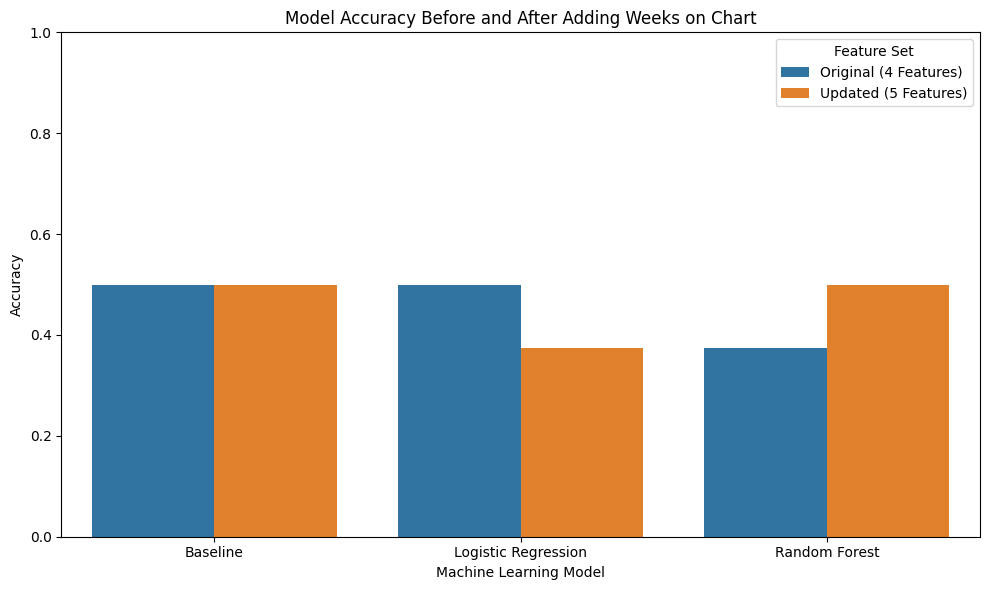

In [122]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

original = results_df.copy()
original["Feature Set"] = "Original (4 Features)"

updated = results_v2_df.copy()
updated["Feature Set"] = "Updated (5 Features)"

comparison = pd.concat(
    [original, updated],
    ignore_index=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    hue="Feature Set"
)

plt.title(
    "Model Accuracy Before and After Adding Weeks on Chart"
)
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(
    "CS418_ML_Accuracy_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


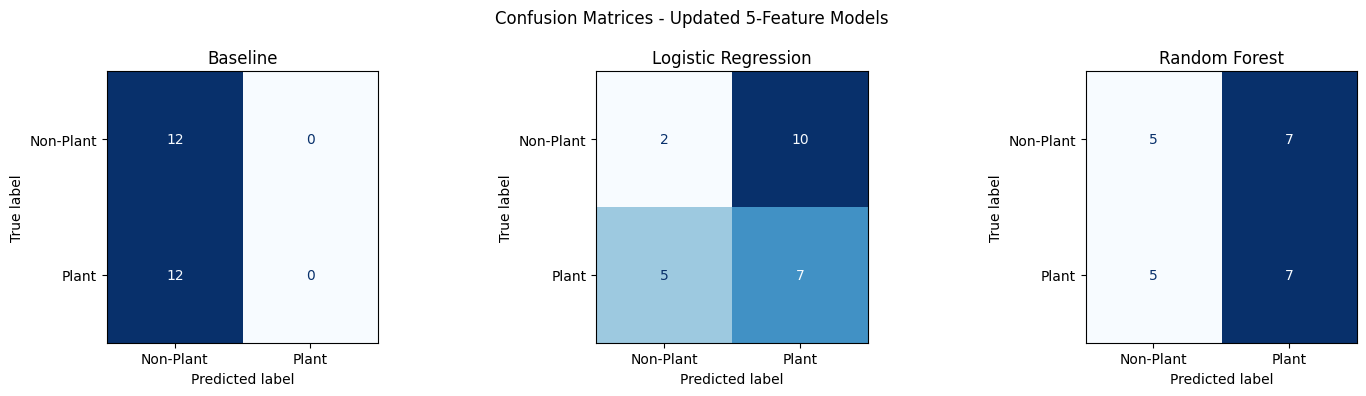

In [123]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):

    predictions = cross_val_predict(
        model,
        X_v2,
        y,
        cv=cv
    )

    cm = confusion_matrix(
        y, predictions, labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Plant", "Plant"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle(
    "Confusion Matrices - Updated 5-Feature Models"
)

plt.tight_layout()

plt.savefig(
    "CS418_ML_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [124]:
df.to_csv("CS418_combined_ML_dataset.csv", index=False)
print("Corrected dataset saved!")

Corrected dataset saved!
